In [80]:
from pyDashNetworkCode import *
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt

#gStore = GapJunctionGraph()
gStore = neuralNet()
app = graphApp(gStore,default_stylesheet)
app.app.run(mode='inline', port=8054,debug=True)
# app = createIonChannelApp(gStore,default_stylesheet)
#saving a graph after you removed nodes doesnt really work
#i think the edges dont get updated 


In [ ]:
#NOTE: NMDA needs to be split in 2 because Ca has a different reversal potential compared to the other 2 cations. 
#When V>0 current goes negative, we get negative Ca influx, and eventually negative Ca values, which are incorrect. 


In [81]:
from auxillaryFunctions import *
np.random.seed(0)
STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
STNbias = -2.5
TS = 0.05
delay = TS
nNeurons = len(gStore.G.nodes)

STNDendriteMap = []
STNDendriteInfo = []
STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias) for i in range(nNeurons)]
neuronDict = {"STN":STNNeurons}
baseConductance = 0.02
synapses = {"exc":[genAMPA(TS,0.6*baseConductance,conductanceGain=1,thetaP = 2e-5,thetaD=1e-5,gammaP=0.1,gammaD=0.01,rate=0.01),
                        genNMDA_Ca(TS,5*baseConductance,conductanceGain=1,thetaP = 2e-5,thetaD=1e-5,gammaP=0.1,gammaD=0.01,rate=0.01),],
                "inh":[genGABA(TS,0.2,conductanceGain=1,thetaP = 2e-5,thetaD=1e-5,gammaP=0.1,gammaD=0.01,rate=0.01)]}

synapseData = []
for key, val in gStore.G.edges.items():
    e0,e1 = key
    synapseType = val["synapseType"]
    cond = ast.literal_eval(val["conductance"])
    for synapseInfo in synapses[synapseType]:
        synapseInfo = deepcopy(synapseInfo)
        synapseInfo["conductance"] = cond*synapseInfo["conductance"] 
        preName = "STN" #gStore.G.nodes[e0]["label"]
        postName = "STN" #gStore.G.nodes[e1]["label"]
        synDat = {"pre":e0,"post":e1,"synapse":deepcopy(synapseInfo),
                "delay":delay,"preName":preName,"postName":postName,"segmentIndex":0}
        synapseData.append(synDat)

synapseDict = {"all":synapseData}
simData,connectionToChannelMap = genSimData(neuronDict,{},synapseDict,TS)
print(f"Total number of channels {simData['nChannels']}")

Total number of channels 26


c:\Users\CathalMcLoughlin\Documents\GitHub\pythonCPPtesting.ipynb\auxillaryFunctions.py:49: RuntimeWarning:

overflow encountered in exp



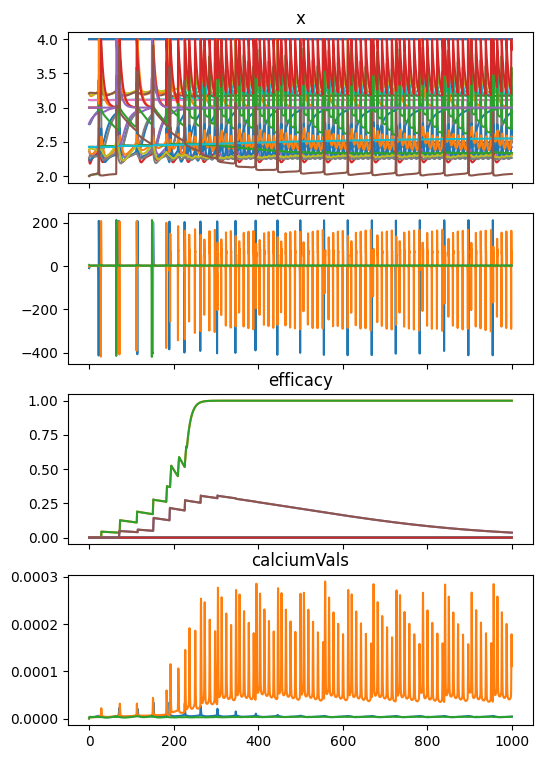

In [82]:
stimInfoSpikes = {}
syns = [i for i,n in enumerate(simData["name"]) if n == "AMPAR"] #"AMPAR" #GABA
#stimSynapse(stimInfoSpikes,syns,50,100,TS)

runTime = 1000
stimInfoCurrents = {} 
# stimBiasCurrent(stimInfoCurrents,segmentsToStim=[0],currentValue=3.0,startTime=100,stopTime=115,TS=TS)

simDataPy = deepcopy(simData)
simDataPy["debugRecording"] = np.zeros_like(simDataPy["current"])
data = solveSystemStandard(simDataPy,TS,runTime,stimInfoSpikes,stimInfoCurrents,vectorized=True,
                           recordingKeys = ["voltages","calciumVals","netCurrent","x","debugRecording","CaChannelCurrent","efficacy"])

keysToPlot = ["x","netCurrent","efficacy","calciumVals","time"]
standardPlot({key:data[key] for key in keysToPlot})
#plt.plot(data["time"],data["debugRecording"][:,synapsesToStim])

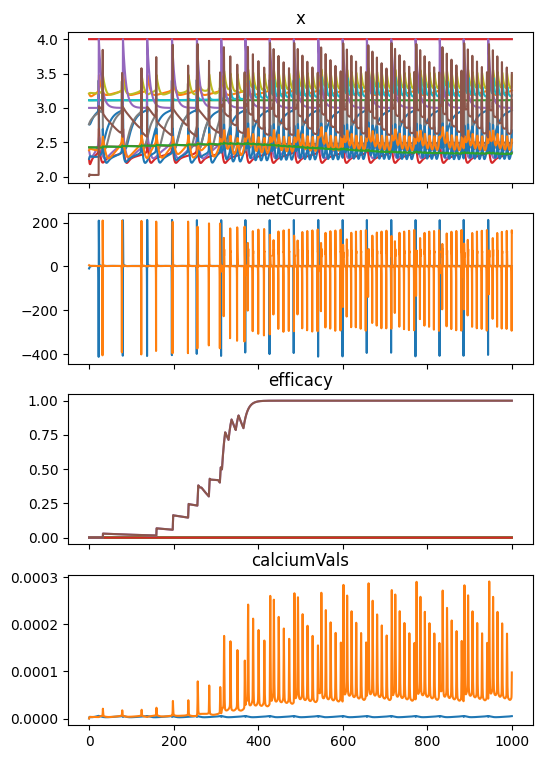

In [75]:
simDataPy2 = deepcopy(simData)
simDataPy2["debugRecording"] = np.zeros_like(simDataPy["current"])
data2 = solveSystemStandard(simDataPy2,TS,runTime,stimInfoSpikes,stimInfoCurrents,vectorized=True,
                           recordingKeys = ["voltages","calciumVals","netCurrent","x","debugRecording","CaChannelCurrent","efficacy"])

standardPlot({key:data2[key] for key in keysToPlot})

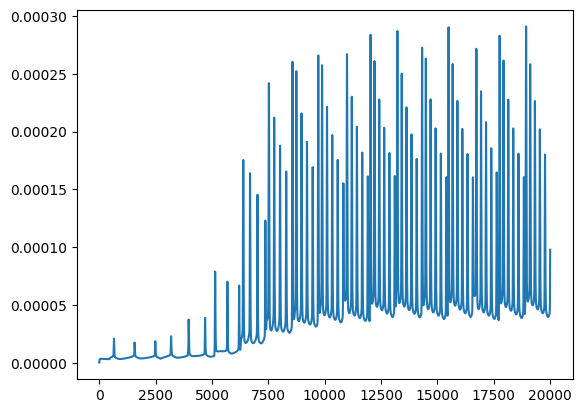

In [83]:
plt.plot(data2["calciumVals"][:,1])

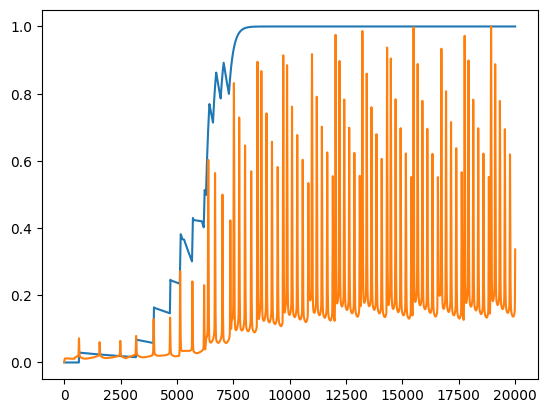

In [76]:
nameDict = {}
for i,k in enumerate(simData["name"]):
    if k not in nameDict.keys():
        nameDict[k] = []
    nameDict[k].append(i)


plt.plot(data2["efficacy"][:,nameDict["NMDAR"][0]])
neurInd = 1
plt.plot(data["calciumVals"][:,neurInd]/np.max(data["calciumVals"][:,neurInd]))

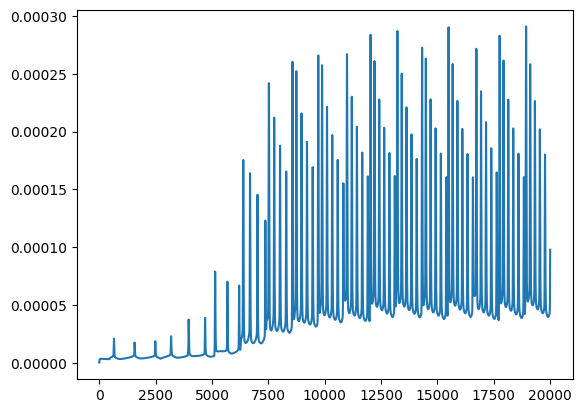

In [77]:
plt.plot(data["calciumVals"][:,1])

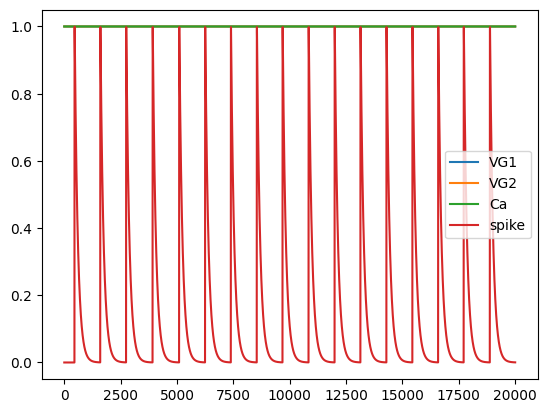

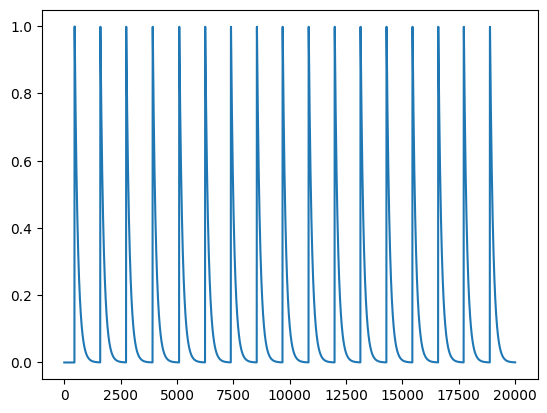

In [78]:
[i for i,e in enumerate(simData["name"]) if e=="NMDAR"]
plt.figure()
plt.plot(data2["x"][:,14,:],label=["VG1","VG2","Ca","spike"])
plt.legend()
plt.figure()
plt.plot(np.prod(data2["x"][:,14,:],axis=1))

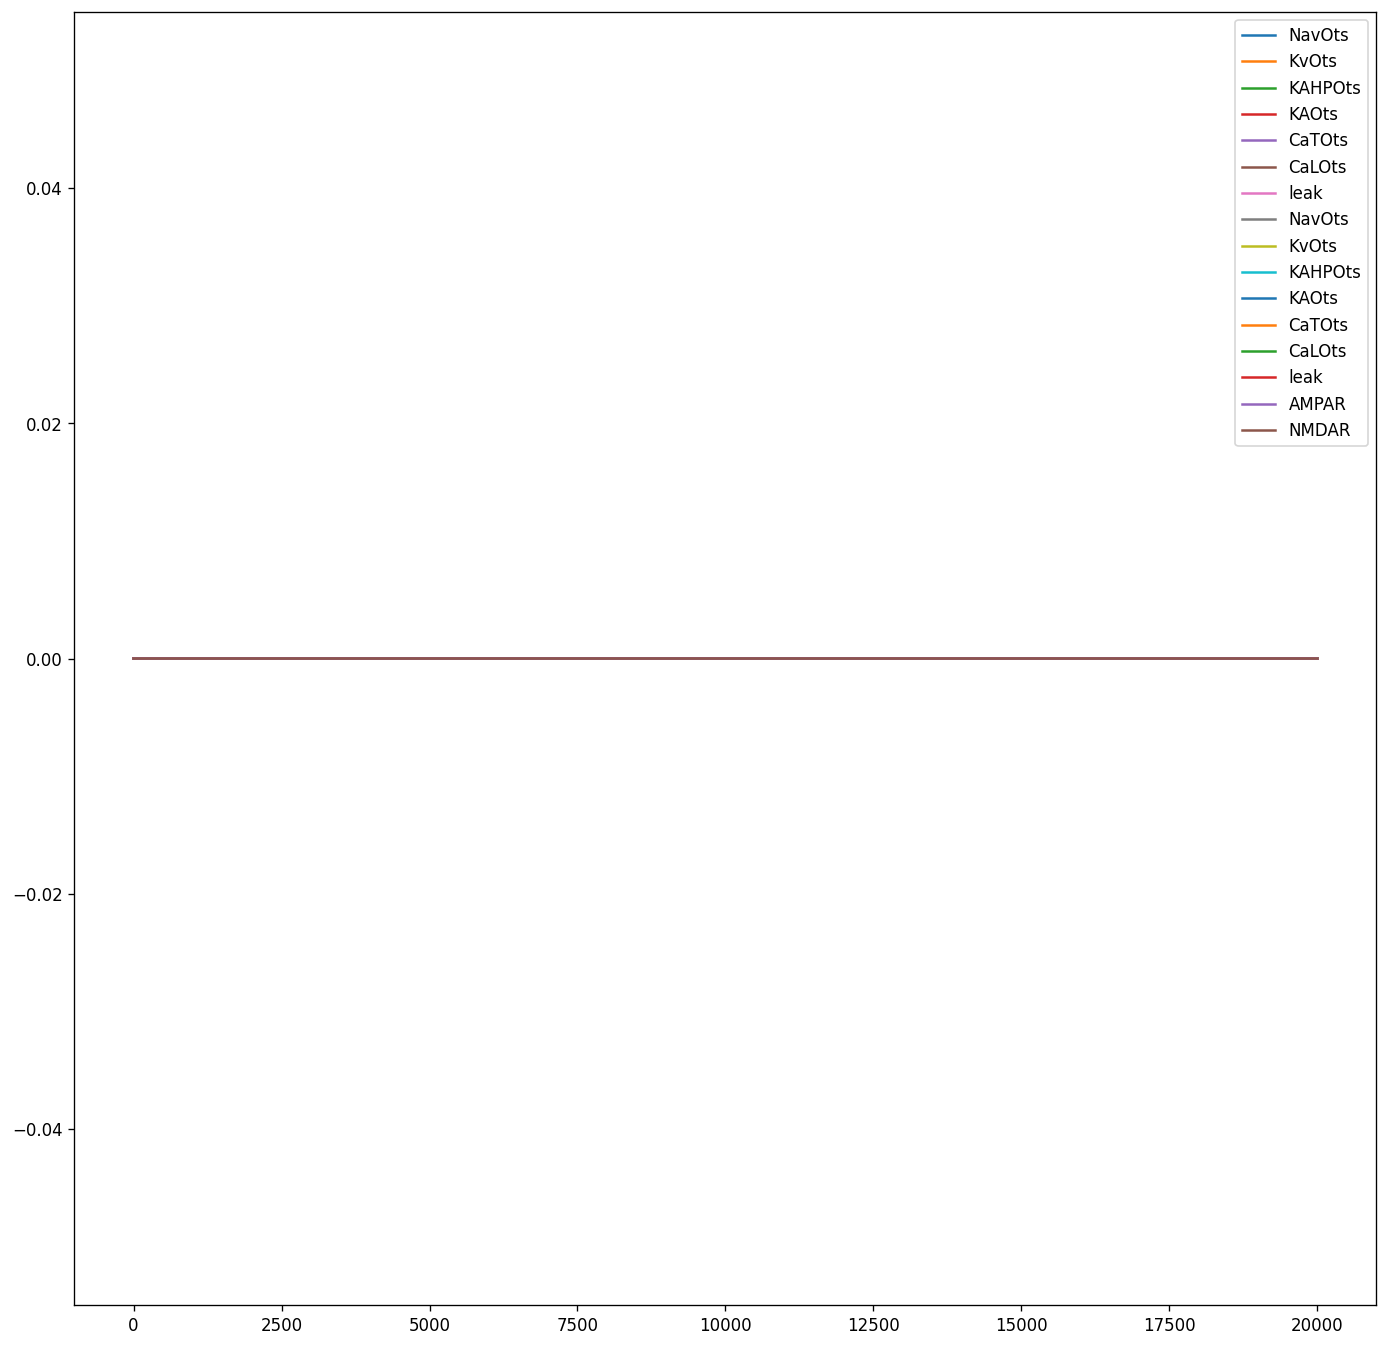

In [79]:
y = data["x"] - data2["x"]
names = simDataPy2["name"]

plt.figure(figsize=(14,14),dpi=120)
plt.plot(y.sum(axis=2)[:,-20::],label=names[-20::]);
plt.legend();

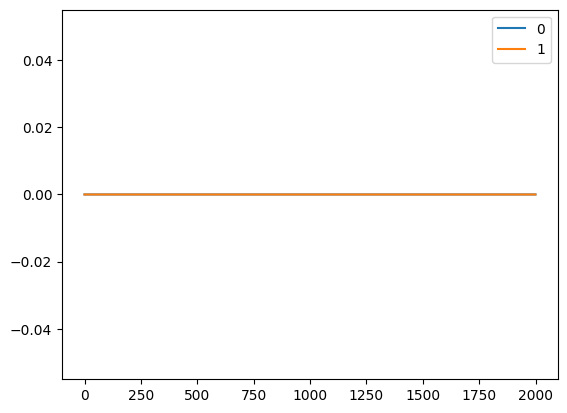

In [29]:
key = "netCurrent"
x =data[key]-data2[key]
plt.plot(x,label=[str(i) for i in range(len(x[0]))])
plt.legend()

In [ ]:
#
a = data["voltages"]-data2["voltages"]
plt.plot(a.T[0])

In [90]:
def sigmoid(z,h,kInv,minOp):
    return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))

def solveGate(x,s,TS,xh,xk,xt0,xt1,xth,xtk,minOpenness):
    xInf = sigmoid(s,xh,xk,minOpenness)#*(xt0+xt1)/TS
    tau = xt0 + xt1*sigmoid(s,xth,xtk,0)
    #return x + TS*(xInf-x)/tau
    return (tau*x + TS*xInf)/(tau+TS)



def fastChannelUpdate(ac,TS,spikeOverwriteList):
    xs = ac["x"].flatten()
    xhs,xks = ac["vHalf"].flatten(),ac["vKi"].flatten()
    xts0,xts1 = ac["tau0"].flatten(),ac["tau1"].flatten()
    xths,xtks = ac["th"].flatten(),ac["tkInv"].flatten()
    V = ac["voltages"][ac["postNeuron"]]
    minOpenness = ac["minOpenness"].flatten()
    Ca = ac["calciumVals"][ac["postNeuron"]]

    #spikeOverwriteList = np.zeros(ac["nChannels"])

    synapseDelay = ac["inputDelay"][i]
    readIndex = ((ac["writeIndex"][ac["channelPreSpiker"]]-synapseDelay)%ac["maxDelayInt"])
    perceivedSpike = ac["spikeBuffer"][ac["channelPreSpiker"]][readIndex].T
    perceivedSpike = np.maximum(spikeOverwriteList,perceivedSpike)[0]

    inputs = np.stack([V,V,Ca,perceivedSpike],-1).flatten()
    res = solveGate(xs,inputs,TS,xhs,xks,xts0,xts1,xths,xtks,minOpenness)
    ac["x"] = res.reshape([-1,4])

def updateCurrents(ac):
    exponents = ac["exponent"].flatten()
    xs = ac["x"].flatten()
    scaled = xs*exponents
    gatingTotal = np.ones(ac["nChannels"])
    np.multiply.at(gatingTotal,np.repeat(np.arange(ac["nChannels"]),4),scaled)

    V = ac["voltages"][ac["postNeuron"]]
    minOpenness = ac["minOpenness"]
    Erev = ac["Erev"]
    g0 = ac["conductance"]
    p = ac["efficacy"]
    w = ac["conductanceGain"]
    CaCurrent = ac["CaCurrent"]

    g = g0 + w*p
    I = g*gatingTotal*(V-Erev) 
    ac["current"] = I
    ac["CaChannelCurrent"] = CaCurrent*I 

ac = simDataPy

In [114]:
def calcWeightChange(p,Ca,rate,gammaP,gammaD,thetaP,thetaD):
    #from the Graupner and Brunel paper
    #rate = 1/tau 
    pStar = 0.5
    revP = (1.0-p)
    fp = -p*revP*(pStar-p)
    potentiation = gammaP*revP*(Ca>thetaP)
    depression = -gammaD*p*(thetaD<Ca)*(Ca<=thetaP)
    Noise = 0
    return rate*fp+potentiation+depression+Noise

p = ac["efficacy"]
Ca = ac["calciumVals"][ac["postNeuron"]]
dp = calcWeightChange(p,Ca,ac["rate"],ac["gammaP"],ac["gammaD"],ac["thetaP"],ac["thetaD"])
ac["efficacy"]+=TS*dp

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)

In [116]:
def calcWeightChangeVectorized(ac,TS):
    rate,gammaP,gammaD,thetaP,thetaD = ac["rate"],ac["gammaP"],ac["gammaD"],ac["thetaP"],ac["thetaD"]
    p = ac["efficacy"]
    Ca = ac["calciumVals"][ac["postNeuron"]]
    #from the Graupner and Brunel paper
    #rate = 1/tau 
    pStar = 0.5
    revP = (1.0-p)
    fp = -p*revP*(pStar-p)
    potentiation = gammaP*revP*(Ca>thetaP)
    depression = -gammaD*p*(thetaD<Ca)*(Ca<=thetaP)
    Noise = 0
    dp = rate*fp+potentiation+depression+Noise
    ac["efficacy"]+=TS*dp

calcWeightChangeVectorized(ac,TS)


In [74]:
perceivedSpike

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [ ]:
readIndex = int((writeIndex[ac["channelPreSpiker"]]-synapseDelay)%ac["maxDelayInt"])
perceivedSpike = ac["spikeBuffer"][ac["channelPreSpiker"]][readIndex]
perceivedSpike = max(perceivedSpike,spikeOverwriteList[i])

In [45]:
ac["x"].flatten()

array([1.17894016e-01, 8.38222504e-01, 1.00000000e+00, 1.00000000e+00,
       2.43112355e-01, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.12185284e-01, 1.00000000e+00,
       3.24623585e-01, 1.93082467e-02, 1.00000000e+00, 1.00000000e+00,
       4.58773106e-01, 9.04160459e-03, 1.00000000e+00, 1.00000000e+00,
       1.30005684e-02, 4.58220869e-01, 9.91892159e-01, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       9.73109305e-02, 8.37145627e-01, 1.00000000e+00, 1.00000000e+00,
       2.25938037e-01, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.11554459e-01, 1.00000000e+00,
       2.96726376e-01, 1.97915062e-02, 1.00000000e+00, 1.00000000e+00,
       4.11975086e-01, 9.07758065e-03, 1.00000000e+00, 1.00000000e+00,
       1.39367860e-02, 4.53818083e-01, 9.91888642e-01, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
      

In [ ]:
tempTS = TS
gatingTotal = 1

for j in range(len(xs)):
    x = xs[j]
    n = exponents[j]
    gatingTotal *= (x**n)
